# Assignment 1 — Task 1: Canada's 2020 Per-Capita Income (Simple Linear Regression)

**Course:** Machine Learning (Undergraduate)
**Deliverable:** Beginner-level single-variable Linear Regression
**Objective (from the assignment PDF):** Predict **Canada's per-capita income for the year 2020** using **linear regression**, with `year` as the single input feature and `per capita income` as the target.

**Dataset:** *Canada Per Capita Income (Single Variable)* — World Bank data distributed via Kaggle:
https://www.kaggle.com/datasets/gurdit559/canada-per-capita-income-single-variable-data-set/data
(The assignment PDF notes the data originally comes from **data.worldbank.org**.)

---

## What this notebook does (roadmap)

1. **Setup** — import libraries and locate the dataset with a robust, relative path.
2. **Load** the real CSV and take a first look.
3. **Inspect** data quality: shape, column types, missing values, duplicates, and year continuity.
4. **EDA** — a clean chronological scatter plot and an outlier check.
5. **Preprocess** — the minimal, justified cleaning steps (and why most are *not* needed here).
6. **Train** a `LinearRegression` model with a **chronological holdout** to get honest error metrics.
7. **Evaluate** with MAE, RMSE, and R², and interpret what we see.
8. **Refit** on all eligible years and **predict 2020**, with a clear final visualization.

> **Leakage rule for this task:** we must never train on 2020-or-later rows. As we will verify below, this dataset ends in **2016**, so no 2020+ rows exist — but we still check explicitly and explain which rows are used.


## 1. Setup

We import the small, standard stack used throughout the course (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`) and set a couple of plotting defaults.

We also locate the **repository root** in a way that works no matter where Jupyter was launched from: we walk upward from the current folder until we find the `data/` directory. This keeps all paths **relative to the repo**, so the notebook runs identically on a Windows machine.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make plots a little nicer and reproducible.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Find the repository root by walking upward until we see the 'data' folder.
def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository root (a folder containing 'data/').")

ROOT = find_repo_root(Path.cwd())
DATA_DIR = ROOT / "data" / "canada"

print("Repository root:", ROOT)
print("Looking for the dataset in:", DATA_DIR)


Repository root: /home/user/ML-Course-Assignments
Looking for the dataset in: /home/user/ML-Course-Assignments/data/canada


## 2. Load the dataset

The Kaggle download for this dataset contains a single CSV. Rather than guessing a hard-coded filename, we **inspect the folder** and read the CSV we actually find — this is more robust and matches the "inspect, don't assume" rule.

**How to get the data (one-time setup):**

```bash
# Option A - Kaggle CLI (after `pip install kaggle` and adding your API token)
kaggle datasets download -d gurdit559/canada-per-capita-income-single-variable-data-set -p data/canada --unzip

# Option B - manual: open the Kaggle link above, download, and unzip into  data/canada/
```

A note on encoding: this file is saved with a **UTF-8 byte-order mark (BOM)**, an invisible marker at the very start. If we read it with plain UTF-8, the first column name becomes `'\ufeffyear'` instead of `'year'`. We therefore use `encoding="utf-8-sig"`, which transparently strips the BOM — a small but real preprocessing decision.


In [2]:
# Find the CSV file(s) inside data/canada and use the first one.
csv_files = sorted(DATA_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(
        f"No CSV found in {DATA_DIR}. Please download the dataset first -\n"
        "  kaggle datasets download -d gurdit559/canada-per-capita-income-single-variable-data-set -p data/canada --unzip"
    )

csv_path = csv_files[0]
print("Loading file:", csv_path.name)

# 'utf-8-sig' removes the invisible BOM so the first column name is clean.
df = pd.read_csv(csv_path, encoding="utf-8-sig")

print("Shape (rows, columns):", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("Last 5 rows:")
display(df.tail())


Loading file: canada_per_capita_income.csv
Shape (rows, columns): (47, 2)

First 5 rows:


,year,per capita income (US$)
0,1970,3399.299037
1,1971,3768.297935
2,1972,4251.175484
3,1973,4804.463248
4,1974,5576.514583


Last 5 rows:


,year,per capita income (US$)
42,2012,42665.25597
43,2013,42676.46837
44,2014,41039.89360
45,2015,35175.18898
46,2016,34229.19363


## 3. Inspect structure and data types

Before cleaning anything, we need to know what we actually have. Here we check the **column names**, the **data types**, and the overall size. The assignment says the data has two columns — `year` and `per capita income` — so we confirm that against the real file instead of assuming it.


In [3]:
print("Columns:", list(df.columns))
print("\nData types:")
print(df.dtypes)
print("\nInfo:")
df.info()


Columns: ['year', 'per capita income (US$)']

Data types:
year                         int64
per capita income (US$)    float64
dtype: object

Info:
<class 'pandas.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   year                     47 non-null     int64  
 1   per capita income (US$)  47 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 884.0 bytes


### Identify the feature and target columns programmatically

To avoid hard-coding invented column names, we **detect** which column is the year (its name contains "year") and which is the income target (the remaining numeric column). All later code uses these detected names, so the notebook would still work if the exact spelling changed.


In [4]:
# Detect the year column by name; the target is the other (numeric) column.
year_col = next(c for c in df.columns if "year" in c.lower())
income_col = next(c for c in df.columns if c != year_col and pd.api.types.is_numeric_dtype(df[c]))

print(f"Feature (input) column : {year_col!r}")
print(f"Target (output) column : {income_col!r}")


Feature (input) column : 'year'
Target (output) column : 'per capita income (US$)'


### Check for missing values and duplicate rows

Real-world data often has gaps or repeated rows, so we check explicitly:

- **Missing values** would break the regression or silently bias it.
- **Duplicate rows** (and specifically duplicate *years*, since each year should appear once) would give some years extra weight.

We report what we find — we only clean problems that actually exist.


In [5]:
print("Missing values per column:")
print(df.isna().sum())

print(f"\nFully duplicated rows: {df.duplicated().sum()}")
print(f"Duplicated years     : {df[year_col].duplicated().sum()}")


Missing values per column:
year                       0
per capita income (US$)    0
dtype: int64

Fully duplicated rows: 0
Duplicated years     : 0


### Check year continuity

Because this is a time series of one row per year, we also verify there are **no missing years** between the first and last year. A gap would matter for a chronological train/validation split later.


In [6]:
years = df[year_col].sort_values().to_numpy()
full_range = set(range(years.min(), years.max() + 1))
missing_years = sorted(full_range - set(years))

print(f"Year range: {years.min()} to {years.max()}  ({len(years)} rows)")
print("Missing years:", missing_years if missing_years else "none - one row per year")


Year range: 1970 to 2016  (47 rows)
Missing years: none - one row per year


### Descriptive statistics

A quick statistical summary (count, mean, standard deviation, min/max, quartiles) gives us a feel for the scale of the income values and helps spot anything obviously wrong (e.g., negative incomes or absurd magnitudes).


In [7]:
display(df.describe())


,year,per capita income (US$)
count,47.000000,47.000000
mean,1993.000000,18920.137063
std,13.711309,12034.679438
min,1970.000000,3399.299037
25%,1981.500000,9526.914515
50%,1993.000000,16426.725480
75%,2004.500000,27458.601420
max,2016.000000,42676.468370


## 4. Exploratory Data Analysis (EDA)

### Chronological scatter plot

The single most informative view for this dataset is **`year` on the x-axis and income on the y-axis**, with points connected in time order. This lets us see:

- whether a **straight line** is a reasonable model at all (the core assumption of linear regression),
- the overall **trend**, and
- any obvious bends or unusual years.


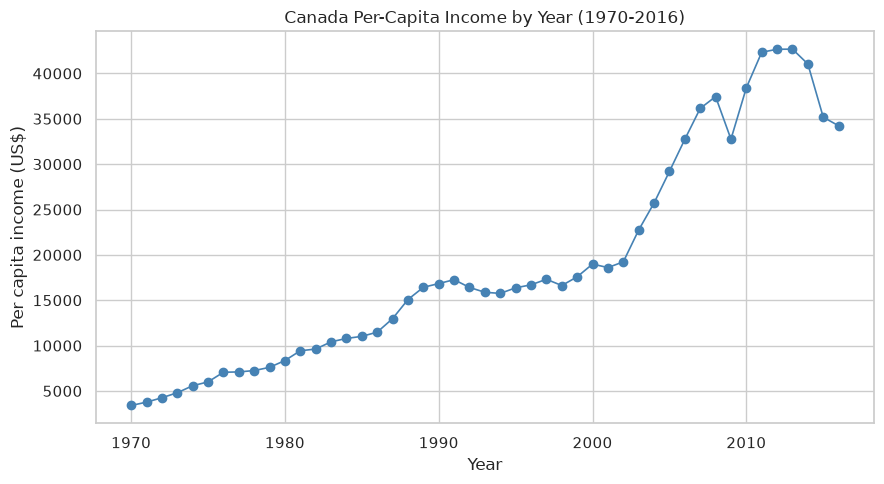

In [8]:
fig, ax = plt.subplots()
ax.plot(df[year_col], df[income_col], marker="o", linewidth=1.2, color="steelblue")
ax.set_title("Canada Per-Capita Income by Year (1970-2016)")
ax.set_xlabel("Year")
ax.set_ylabel("Per capita income (US$)")
ax.ticklabel_format(style="plain", axis="y")  # show full numbers, not scientific notation
plt.tight_layout()
plt.show()


**Interpretation:** income rises fairly steadily from 1970 to about 2008, accelerates, then **flattens and dips around 2015-2016** (this matches the real-world oil-price shock that hit Canada's economy). The long-run trend is roughly linear, but the recent downturn is *not* — keep this in mind when we evaluate the model, because a straight line cannot capture that bend.


### Outlier check

We look for outliers with a **boxplot** and the common **1.5 × IQR rule**: any point more than 1.5 × (interquartile range) below Q1 or above Q3 is flagged.

**Decision rule:** we will only *remove* a point if it is a clear data error. Real economic variation (booms, recessions) is genuine signal, not noise — especially with only 47 rows, deleting valid years would throw away information.


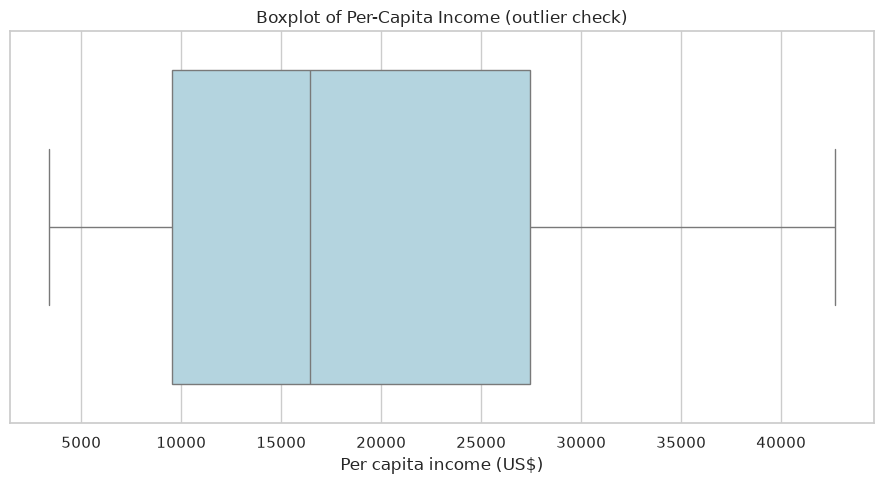

Q1 = 9,526.91, Q3 = 27,458.60, IQR = 17,931.69
1.5*IQR fences: [-17,370.62, 54,356.13]
Outliers flagged: 0


In [9]:
q1 = df[income_col].quantile(0.25)
q3 = df[income_col].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outliers = df[(df[income_col] < lower_fence) | (df[income_col] > upper_fence)]

fig, ax = plt.subplots()
sns.boxplot(x=df[income_col], ax=ax, color="lightblue")
ax.set_title("Boxplot of Per-Capita Income (outlier check)")
ax.set_xlabel("Per capita income (US$)")
plt.tight_layout()
plt.show()

print(f"Q1 = {q1:,.2f}, Q3 = {q3:,.2f}, IQR = {iqr:,.2f}")
print(f"1.5*IQR fences: [{lower_fence:,.2f}, {upper_fence:,.2f}]")
print(f"Outliers flagged: {len(outliers)}")
if len(outliers):
    display(outliers)


**Finding:** no points fall outside the 1.5 × IQR fences, so there are **no outliers to remove**. The data is clean: no missing values, no duplicates, no missing years, and sensible values throughout. The only preprocessing actually required is the BOM handling we already did at load time.


## 5. Preprocessing: build the feature matrix and target vector

`scikit-learn` expects the input `X` as a **2-D** structure (one column per feature) and the target `y` as a **1-D** array. We build both from the detected column names.

We deliberately do **not** scale the features. For a single-variable linear regression, scaling is unnecessary — the model only has to learn one slope and one intercept, and keeping `year` in its original units makes the results (income **per year**, in US$) easy to interpret in plain language.


In [10]:
# X must be 2-D (n_samples, n_features); y is 1-D (n_samples,).
X = df[[year_col]].to_numpy()
y = df[income_col].to_numpy()

print("X shape:", X.shape, "| y shape:", y.shape)
print("First 3 X rows:\n", X[:3].ravel())
print("First 3 y values:", y[:3])


X shape: (47, 1) | y shape: (47,)
First 3 X rows:
 [1970 1971 1972]
First 3 y values: [3399.299037 3768.297935 4251.175484]


## 6. Train a model with a chronological holdout (honest evaluation)

**Why not train on everything immediately?** If we fit the model on all rows and then "evaluate" on those same rows, the score would be overconfident. To get an honest estimate of how well the model predicts *unseen* years, we hold out the **most recent years** as a validation set:

- **Training set:** 1970-2011
- **Validation set:** 2012-2016 (the last 5 years)

A **chronological** split (not a random shuffle) is the correct choice for time-ordered data — it mimics the real task of predicting the future from the past and avoids leaking future information into training.

**Leakage check for 2020:** we verified above that the data ends in **2016**, so *no 2020-or-later rows exist* and none can leak into training. Our split only ever uses pre-2020 data.

> `LinearRegression` is deterministic (a closed-form least-squares solution), so no `random_state` is needed; the split itself is a fixed year cut-off, which is also fully deterministic.


In [11]:
CUTOFF_YEAR = 2011  # train on <= 2011, validate on 2012-2016

train_mask = df[year_col] <= CUTOFF_YEAR
X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[~train_mask], y[~train_mask]

print(f"Training rows  : {len(X_train)}  (years {X_train.min()}-{X_train.max()})")
print(f"Validation rows: {len(X_val)}  (years {X_val.min()}-{X_val.max()})")

model = LinearRegression()
model.fit(X_train, y_train)
print("\nModel trained on pre-2012 data.")


Training rows  : 42  (years 1970-2011)
Validation rows: 5  (years 2012-2016)

Model trained on pre-2012 data.


## 7. Evaluate on the held-out years

We predict the validation years and compute three standard regression metrics:

- **MAE** (Mean Absolute Error) — average absolute dollar error; easy to interpret.
- **RMSE** (Root Mean Squared Error) — like MAE but punishes large errors more.
- **R²** (coefficient of determination) — 1.0 is perfect; 0 means "no better than predicting the mean"; **negative** means *worse* than just predicting the mean of the validation years.


In [12]:
y_val_pred = model.predict(X_val)

mae = mean_absolute_error(y_val, y_val_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
r2 = r2_score(y_val, y_val_pred)

print(f"Validation MAE : US$ {mae:,.2f}")
print(f"Validation RMSE: US$ {rmse:,.2f}")
print(f"Validation R^2 : {r2:.4f}")

comparison = pd.DataFrame({
    "Year": X_val.ravel(),
    "Actual (US$)": y_val,
    "Predicted (US$)": np.round(y_val_pred, 2),
})
comparison["Error (US$)"] = np.round(comparison["Actual (US$)"] - comparison["Predicted (US$)"], 2)
display(comparison)


Validation MAE : US$ 5,364.34
Validation RMSE: US$ 6,417.59
Validation R^2 : -2.0116


,Year,Actual (US$),Predicted (US$),Error (US$)
0,2012,42665.25597,33274.32,9390.94
1,2013,42676.46837,34054.01,8622.46
2,2014,41039.89360,34833.71,6206.18
3,2015,35175.18898,35613.40,-438.21
4,2016,34229.19363,36393.09,-2163.90


### Visualize the holdout fit

Plotting the training points, the true validation points, and the model's predictions side by side makes the errors concrete and easy to see.


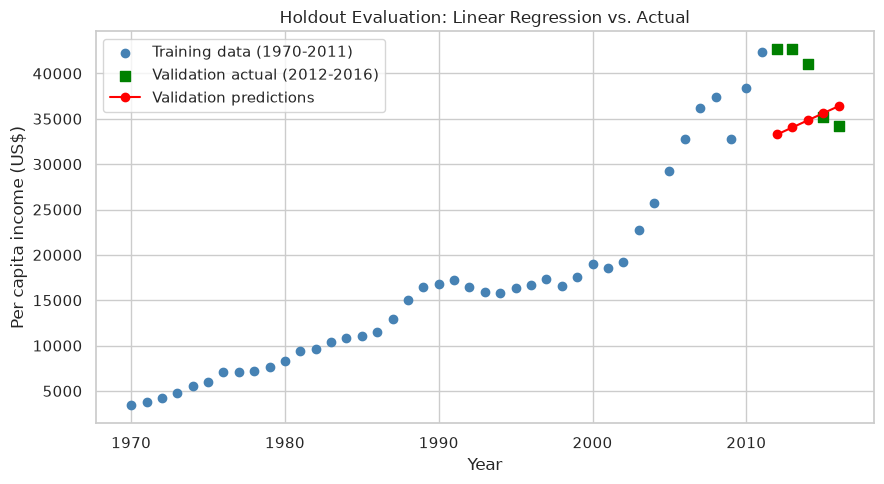

In [13]:
fig, ax = plt.subplots()
ax.scatter(X_train, y_train, color="steelblue", label="Training data (1970-2011)")
ax.scatter(X_val, y_val, color="green", marker="s", s=60, label="Validation actual (2012-2016)")
ax.plot(X_val, y_val_pred, color="red", marker="o", linewidth=1.5, label="Validation predictions")
ax.set_title("Holdout Evaluation: Linear Regression vs. Actual")
ax.set_xlabel("Year")
ax.set_ylabel("Per capita income (US$)")
ax.legend()
plt.tight_layout()
plt.show()


**Interpretation (be honest about the negative R²):** the model, trained only through 2011, **over-predicts** 2012-2016. That is because income plateaued and then *fell* in 2015-2016 (the oil-price shock), a bend a straight line trained on the earlier growth years cannot anticipate. The negative R² is not a bug — it is the truthful result of asking a linear model to extrapolate a trend that changed. This is exactly why we evaluate on held-out *future* years rather than on the training data.


## 8. Refit on all eligible years and read the coefficients

Now that we have an honest estimate of the error, we follow best practice and **refit the model on all eligible data** (every pre-2020 row, i.e., all of 1970-2016). Using more data gives the most reliable final line for the 2020 prediction.

We then read the two learned parameters in plain language:

- the **slope (coefficient)** = how many extra US dollars of income the model associates with each additional year,
- the **intercept** = the model's income value at year 0 (not meaningful on its own — it is just where the line crosses the y-axis).


In [14]:
final_model = LinearRegression()
final_model.fit(X, y)  # all eligible (pre-2020) rows

slope = final_model.coef_[0]
intercept = final_model.intercept_
r2_all = final_model.score(X, y)

print(f"Slope (coefficient) : {slope:,.4f}  -> income grows by about US$ {slope:,.2f} per year")
print(f"Intercept           : {intercept:,.2f}")
print(f"R^2 on all data     : {r2_all:.4f}  -> the line explains ~{r2_all*100:.1f}% of the variation in income")


Slope (coefficient) : 828.4651  -> income grows by about US$ 828.47 per year
Intercept           : -1,632,210.76
R^2 on all data     : 0.8909  -> the line explains ~89.1% of the variation in income


## 9. Predict Canada's per-capita income for 2020

This is the assignment's actual question. We feed the year **2020** into the final model. Because 2020 is outside the observed range (1970-2016), this is an **extrapolation** — we will flag that in the conclusion.


In [15]:
predicted_2020 = final_model.predict([[2020]])[0]

print("=" * 55)
print(f"Predicted Canada per-capita income in 2020: US$ {predicted_2020:,.2f}")
print("=" * 55)


Predicted Canada per-capita income in 2020: US$ 41,288.69


### Final visualization: the fitted line and the 2020 prediction

A single summary plot shows the historical data, the fitted regression line extended to 2020, and the predicted 2020 value highlighted so the answer is visually obvious.


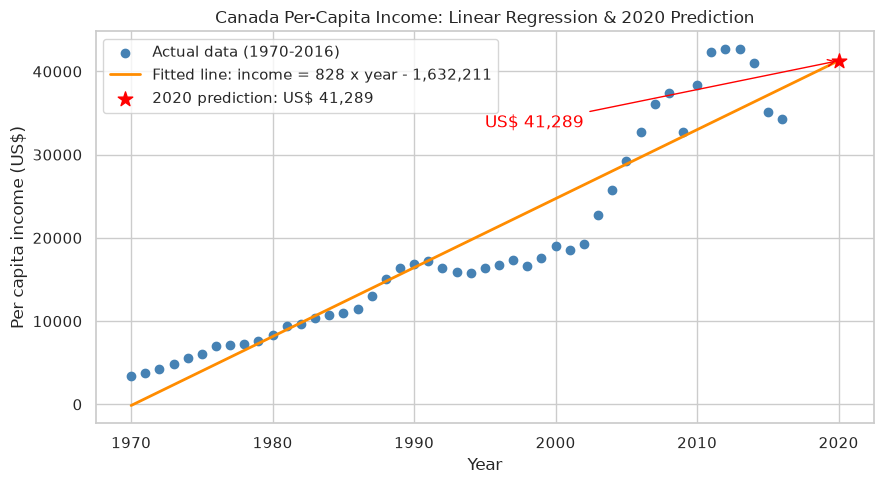

In [16]:
# A smooth line from the first year to 2020.
line_years = np.linspace(df[year_col].min(), 2020, 300).reshape(-1, 1)
line_income = final_model.predict(line_years)

fig, ax = plt.subplots()
ax.scatter(df[year_col], df[income_col], color="steelblue", label="Actual data (1970-2016)")
ax.plot(line_years, line_income, color="darkorange", linewidth=2,
        label=f"Fitted line: income = {slope:,.0f} x year {'+' if intercept >= 0 else '-'} {abs(intercept):,.0f}")
ax.scatter([2020], [predicted_2020], color="red", s=120, zorder=5, marker="*",
           label=f"2020 prediction: US$ {predicted_2020:,.0f}")
ax.annotate(f"US$ {predicted_2020:,.0f}", xy=(2020, predicted_2020),
            xytext=(1995, predicted_2020 - 8000),
            arrowprops=dict(arrowstyle="->", color="red"), color="red")
ax.set_title("Canada Per-Capita Income: Linear Regression & 2020 Prediction")
ax.set_xlabel("Year")
ax.set_ylabel("Per capita income (US$)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


## 10. Results summary

The cell below gathers every important number in one place, computed live from the objects we created (nothing is typed in by hand). This is the authoritative summary; the conclusion that follows interprets it.


In [17]:
print("RESULTS SUMMARY")
print("-" * 55)
print(f"Rows used (all pre-2020)      : {len(df)}  (years {df[year_col].min()}-{df[year_col].max()})")
print(f"Holdout split                 : train <= {CUTOFF_YEAR}, validate {CUTOFF_YEAR+1}-{df[year_col].max()}")
print(f"Validation MAE / RMSE         : US$ {mae:,.2f} / US$ {rmse:,.2f}")
print(f"Validation R^2                : {r2:.4f}")
print(f"Final slope (US$ per year)    : {slope:,.2f}")
print(f"Final intercept               : {intercept:,.2f}")
print(f"Final R^2 (all data)          : {r2_all:.4f}")
print("-" * 55)
print(f">>> 2020 PREDICTION           : US$ {predicted_2020:,.2f}")


RESULTS SUMMARY
-------------------------------------------------------
Rows used (all pre-2020)      : 47  (years 1970-2016)
Holdout split                 : train <= 2011, validate 2012-2016
Validation MAE / RMSE         : US$ 5,364.34 / US$ 6,417.59
Validation R^2                : -2.0116
Final slope (US$ per year)    : 828.47
Final intercept               : -1,632,210.76
Final R^2 (all data)          : 0.8909
-------------------------------------------------------
>>> 2020 PREDICTION           : US$ 41,288.69


## 11. Conclusion

**Answer to the assignment question:** using simple linear regression trained on all available pre-2020 data (1970-2016), Canada's predicted per-capita income for **2020** is approximately **US$41,289** (the exact computed value is printed in the summary above).

### What we did
- Loaded and inspected the real dataset: **47 rows (1970-2016)**, 2 columns (`year`, `per capita income (US$)`), with **no missing values, no duplicates, no missing years, and no outliers**.
- Kept preprocessing minimal and justified (BOM-aware reading; no scaling; no row removal).
- Evaluated honestly with a **chronological holdout** (train 1970-2011, validate 2012-2016).
- Refit on all eligible years and predicted 2020.

### Limitations (read these!)
1. **Extrapolation:** 2020 is outside the observed 1970-2016 range, so the prediction assumes the historical linear trend continues — there is no guarantee.
2. **The trend bent:** income actually fell in 2015-2016 (the oil-price shock), which a straight line cannot model. This is why the holdout R² was negative — an honest and instructive result.
3. **Real-world 2020:** the COVID-19 pandemic sharply affected actual 2020 incomes; a model trained only on pre-2020 data cannot know this. The prediction is a *trend estimate*, not a measurement.
4. **Tiny dataset:** 47 points and a single feature make this a learning exercise, not a production forecast.

**Bottom line:** simple linear regression gives a clear, interpretable answer and is a great first model, but its honesty about its own limits (the negative holdout R²) is the most valuable lesson here.
